<img src="../../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Data Visualisation with Plotly - Solution

---

## Learning Objectives

In this lesson, we’ll explore the range of interactive visualizations offered by Plotly, reinforce our knowledge of static visualizations in pandas and Matplotlib, and use Plotly to build interactive charts and graphs

*After completing this notebook, you will be able to:*

- Visualise data with a range of different charts 
- Use Pandas and Plotly to produce these charts
- Interpret the results of the visualisations

<a id="visualisations"></a>

# Visualisations
---

In this section, we'll learn about how plotting works in Pandas and Matplotlib. 

It'a important to know that Pandas uses Matplotlib behind the scenes to make plots. 

So, you will notice that Pandas plotting methods often use similar parameter names as Matplotlib methods. You can also use Matplotlib functions in combination with Pandas methods to alter the plots after drawing them. 

For example, you can use Matplotlib's `xlabel` and `title` functions to label the plot's x-axis and title, respectively, after it is drawn.

As we explore different types of plots, notice:

1. Different types of plots are drawn very similarly; they even tend to share parameter names.

2. In Pandas, calling `plot()` on a `DataFrame` is different to calling it on a `Series`. Although the methods are both named `plot`, they may take different parameters.

Toward the end of the lab, we will show some motivational plots using Seaborn, a popular statistics plotting library, as well as go more in-depth about how Matplotlib works.

Pandas documentation is a good, comprehensive source of information on different plotting functions and parameters.

[Link to Documentation](http://pandas.pydata.org/pandas-docs/stable/generated/pandas.DataFrame.plot.html)

Let's start by importing the libraries we'll be using.

In [1]:
# Numpy and Pandas for data manipulation
import pandas as pd
import numpy as np

# Import the two data visualisation libraries we'll be using
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Set some formatting parameters for this notebook
plt.style.use('fivethirtyeight')

In [3]:
# Increase default figure and font sizes for easier viewing.
plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['font.size'] = 14

# Visualizing property data
---

Let’s imagine we’re working with **one of the USA’s largest property buying websites.**

At the moment, their process for deciding on the selling price for a property involves sending an estate agent to the house. The agent uses their experience and gut instinct to decide on a valuation for the property.

Your client wants to switch to a more data-driven method for property valuation, for two main reasons:
1. In-person valuations are less practical during the coronavirus pandemic. 
2. Competitors are adopting a more data-driven approach.

You need to perform an exploratory data analysis to:
1. Find out which characteristics of a property are the strongest predictors of its sale price
2. Produce visualizations to communicate this
3. Interpret and sense check your findings before presenting them



## <font color='green'> Exercise: Reading in house price data
---

    
We’ll be using the Ames housing data set, which shows the real sale prices and characteristics of over 1,000 houses in Iowa.

Take a few minutes to read more about the dataset here: https://www.kaggle.com/c/house-prices-advanced-regression-techniques
    
Also take a look at the data dictionary below, and familiarise yourself with the columns:
    
* LotFrontage: Linear feet of street connected to property
    
* HouseStyle: Style of dwelling
	
       1Story	One story
       1.5Fin	One and one-half story: 2nd level finished
       1.5Unf	One and one-half story: 2nd level unfinished
       2Story	Two story
       2.5Fin	Two and one-half story: 2nd level finished
       2.5Unf	Two and one-half story: 2nd level unfinished
       SFoyer	Split Foyer
       SLvl	  Split Level
    
* MSZoning: Identifies the general zoning classification of the sale.
		
       A	 Agriculture
       C	 Commercial
       FV	Floating Village Residential
       I	 Industrial
       RH	Residential High Density
       RL	Residential Low Density
       RP	Residential Low Density Park 
       RM	Residential Medium Density
    
* LotArea: Lot size in square feet

* OverallQual: Rates the overall material and finish of the house

       10   Very Excellent
       9	Excellent
       8	Very Good
       7	Good
       6	Above Average
       5	Average
       4	Below Average
       3	Fair
       2	Poor
       1	Very Poor
	
* OverallCond: Rates the overall condition of the house

       10   Very Excellent
       9	Excellent
       8	Very Good
       7	Good
       6	Above Average	
       5	Average
       4	Below Average	
       3	Fair
       2	Poor
       1	Very Poor

* YearBuilt: Original construction date

* YearRemodAdd: Remodel date (same as construction date if no remodeling or additions)

* TotalBsmtSF: Total square feet of basement area

* 1stFlrSF: First Floor square feet
 
* 2ndFlrSF: Second floor square feet

* LowQualFinSF: Low quality finished square feet (all floors)

* GrLivArea: Above grade (ground) living area square feet

* FullBath: Full bathrooms above grade

* HalfBath: Half baths above grade

* Bedroom: Bedrooms above grade (does NOT include basement bedrooms)

* Kitchen: Kitchens above grade
       	
* TotRmsAbvGrd: Total rooms above grade (does not include bathrooms)

* Fireplaces: Number of fireplaces
		
* GarageYrBlt: Year garage was built
		
* GarageCars: Size of garage in car capacity

* GarageArea: Size of garage in square feet

* WoodDeckSF: Wood deck area in square feet

* OpenPorchSF: Open porch area in square feet

* EnclosedPorch: Enclosed porch area in square feet

Then, read in the file `iowa_houses.csv` from the `data` directory in this folder. Call it `houses`

In [4]:
houses = pd.read_csv('../data/iowa_houses.csv')
houses.head()

,Neighborhood,LotArea,MSZoning,HouseStyle,LotFrontage,OverallQual,OverallCond,YearBuilt,YearRemodAdd,TotalBsmtSF,...,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,SalePrice
0,CollgCr,8450,RL,2Story,65.0,7,5,2003,2003,856,...,1,8,0,2003.0,2,548,0,61,0,208500
1,Veenker,9600,RL,1Story,80.0,6,8,1976,1976,1262,...,1,6,1,1976.0,2,460,298,0,0,181500
2,CollgCr,11250,RL,2Story,68.0,7,5,2001,2002,920,...,1,6,1,2001.0,2,608,0,42,0,223500
3,Crawfor,9550,RL,2Story,60.0,7,5,1915,1970,756,...,1,7,1,1998.0,3,642,0,35,272,140000
4,NoRidge,14260,RL,2Story,84.0,8,5,2000,2000,1145,...,1,9,1,2000.0,3,836,192,84,0,250000


In [5]:
houses.columns

Index(['Neighborhood', 'LotArea', 'MSZoning', 'HouseStyle', 'LotFrontage',
       'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea',
       'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', 'SalePrice'],
      dtype='object')

How many rows and columns are in the dataset?

In [6]:
houses.shape

(1460, 27)

<a id="histograms"></a>

# Histograms
---

Histograms show the spread or distribution of values for a single variable.

Histograms can help us identify:
- Whether a variable is normally distributed (a bell curve).
- Whether a variable contains lots of outliers.

This can help us to decide whether:
- A variable is suitable for being included as a feature in a model. (Some models rely on features being normally distributed, with few or no outliers.)
- Outliers need to be handled or removed.


Let's create a histogram to show the spread of total lot areas.

<Axes: >

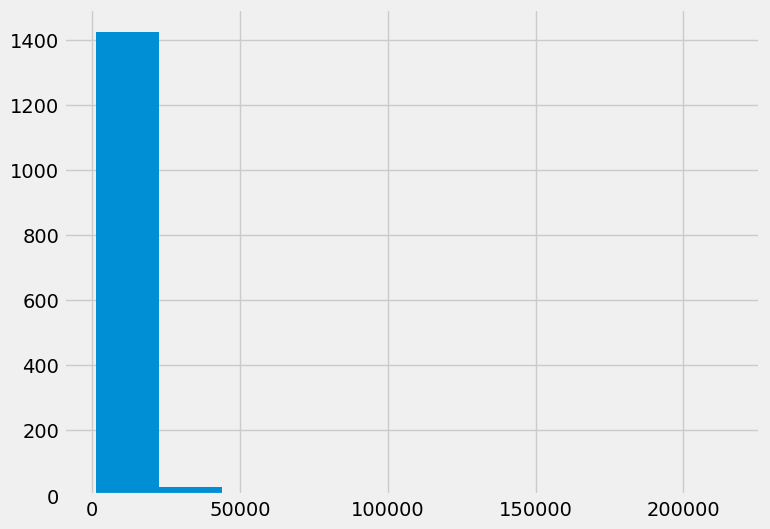

In [7]:
houses['LotArea'].hist()

Can we change the number of bins to make this easier to read?

<Axes: >

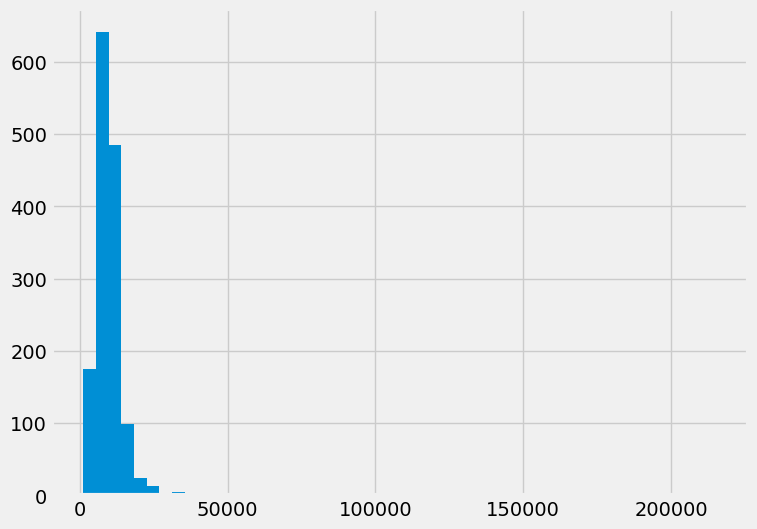

In [8]:
houses['LotArea'].hist(bins=50)

Finally, let's restrict the range on the x axis.

<Axes: >

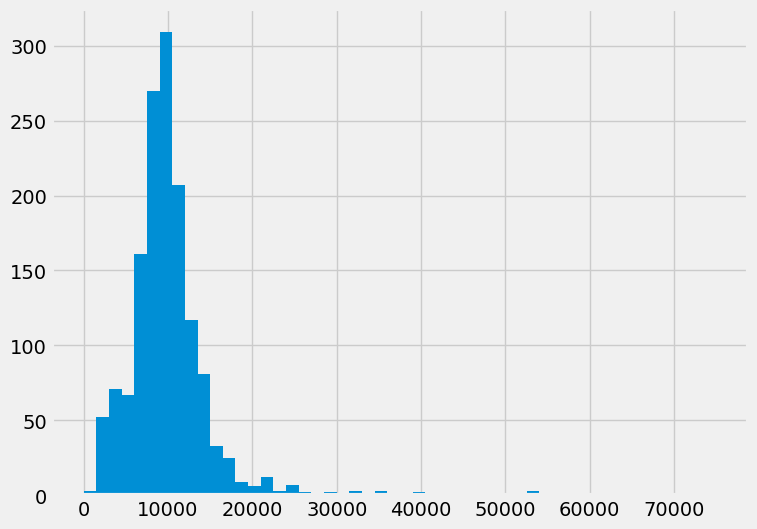

In [9]:
houses['LotArea'].hist(bins=50, range=(0,75000))

What does this histogram tell us?

* The most common area bracket is between 9000-11000 square feet. 
* There are some outliers, mostly towards the higher end of lot areas.
* This column is roughly normally distributed.


## <font color='green'> Exercise: Histograms
---
    
Make histograms to show the spread of each of these variables, adjusting the number of bins and the x-axis range to make them as readable as possible:
* Total rooms above ground
* Garage area


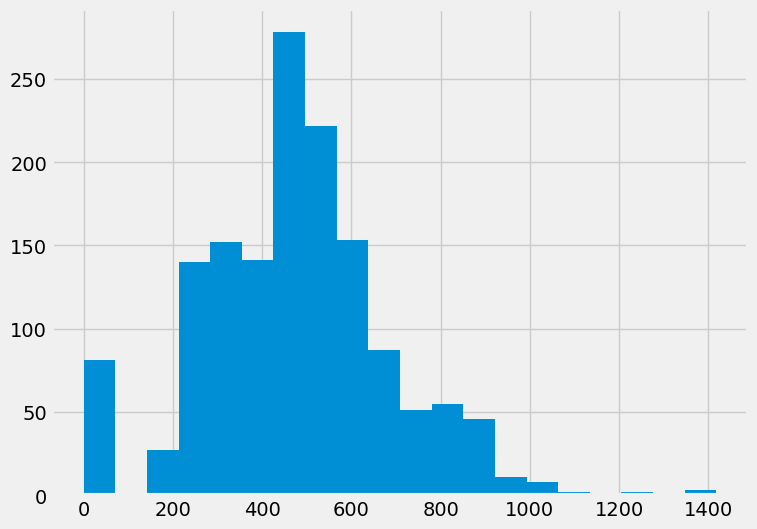

In [10]:
houses['GarageArea'].hist(bins=20);

<Axes: >

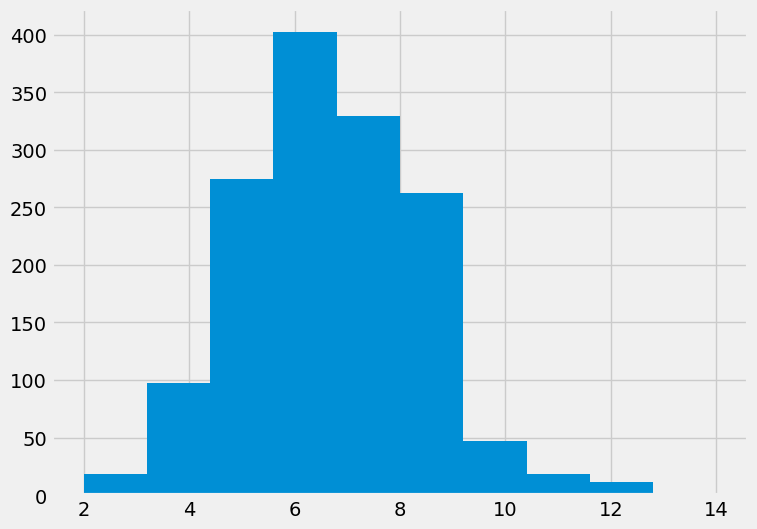

In [11]:
houses['TotRmsAbvGrd'].hist()

We can use the `hist` method on a whole dataframe to get histograms for every variable, in one step.

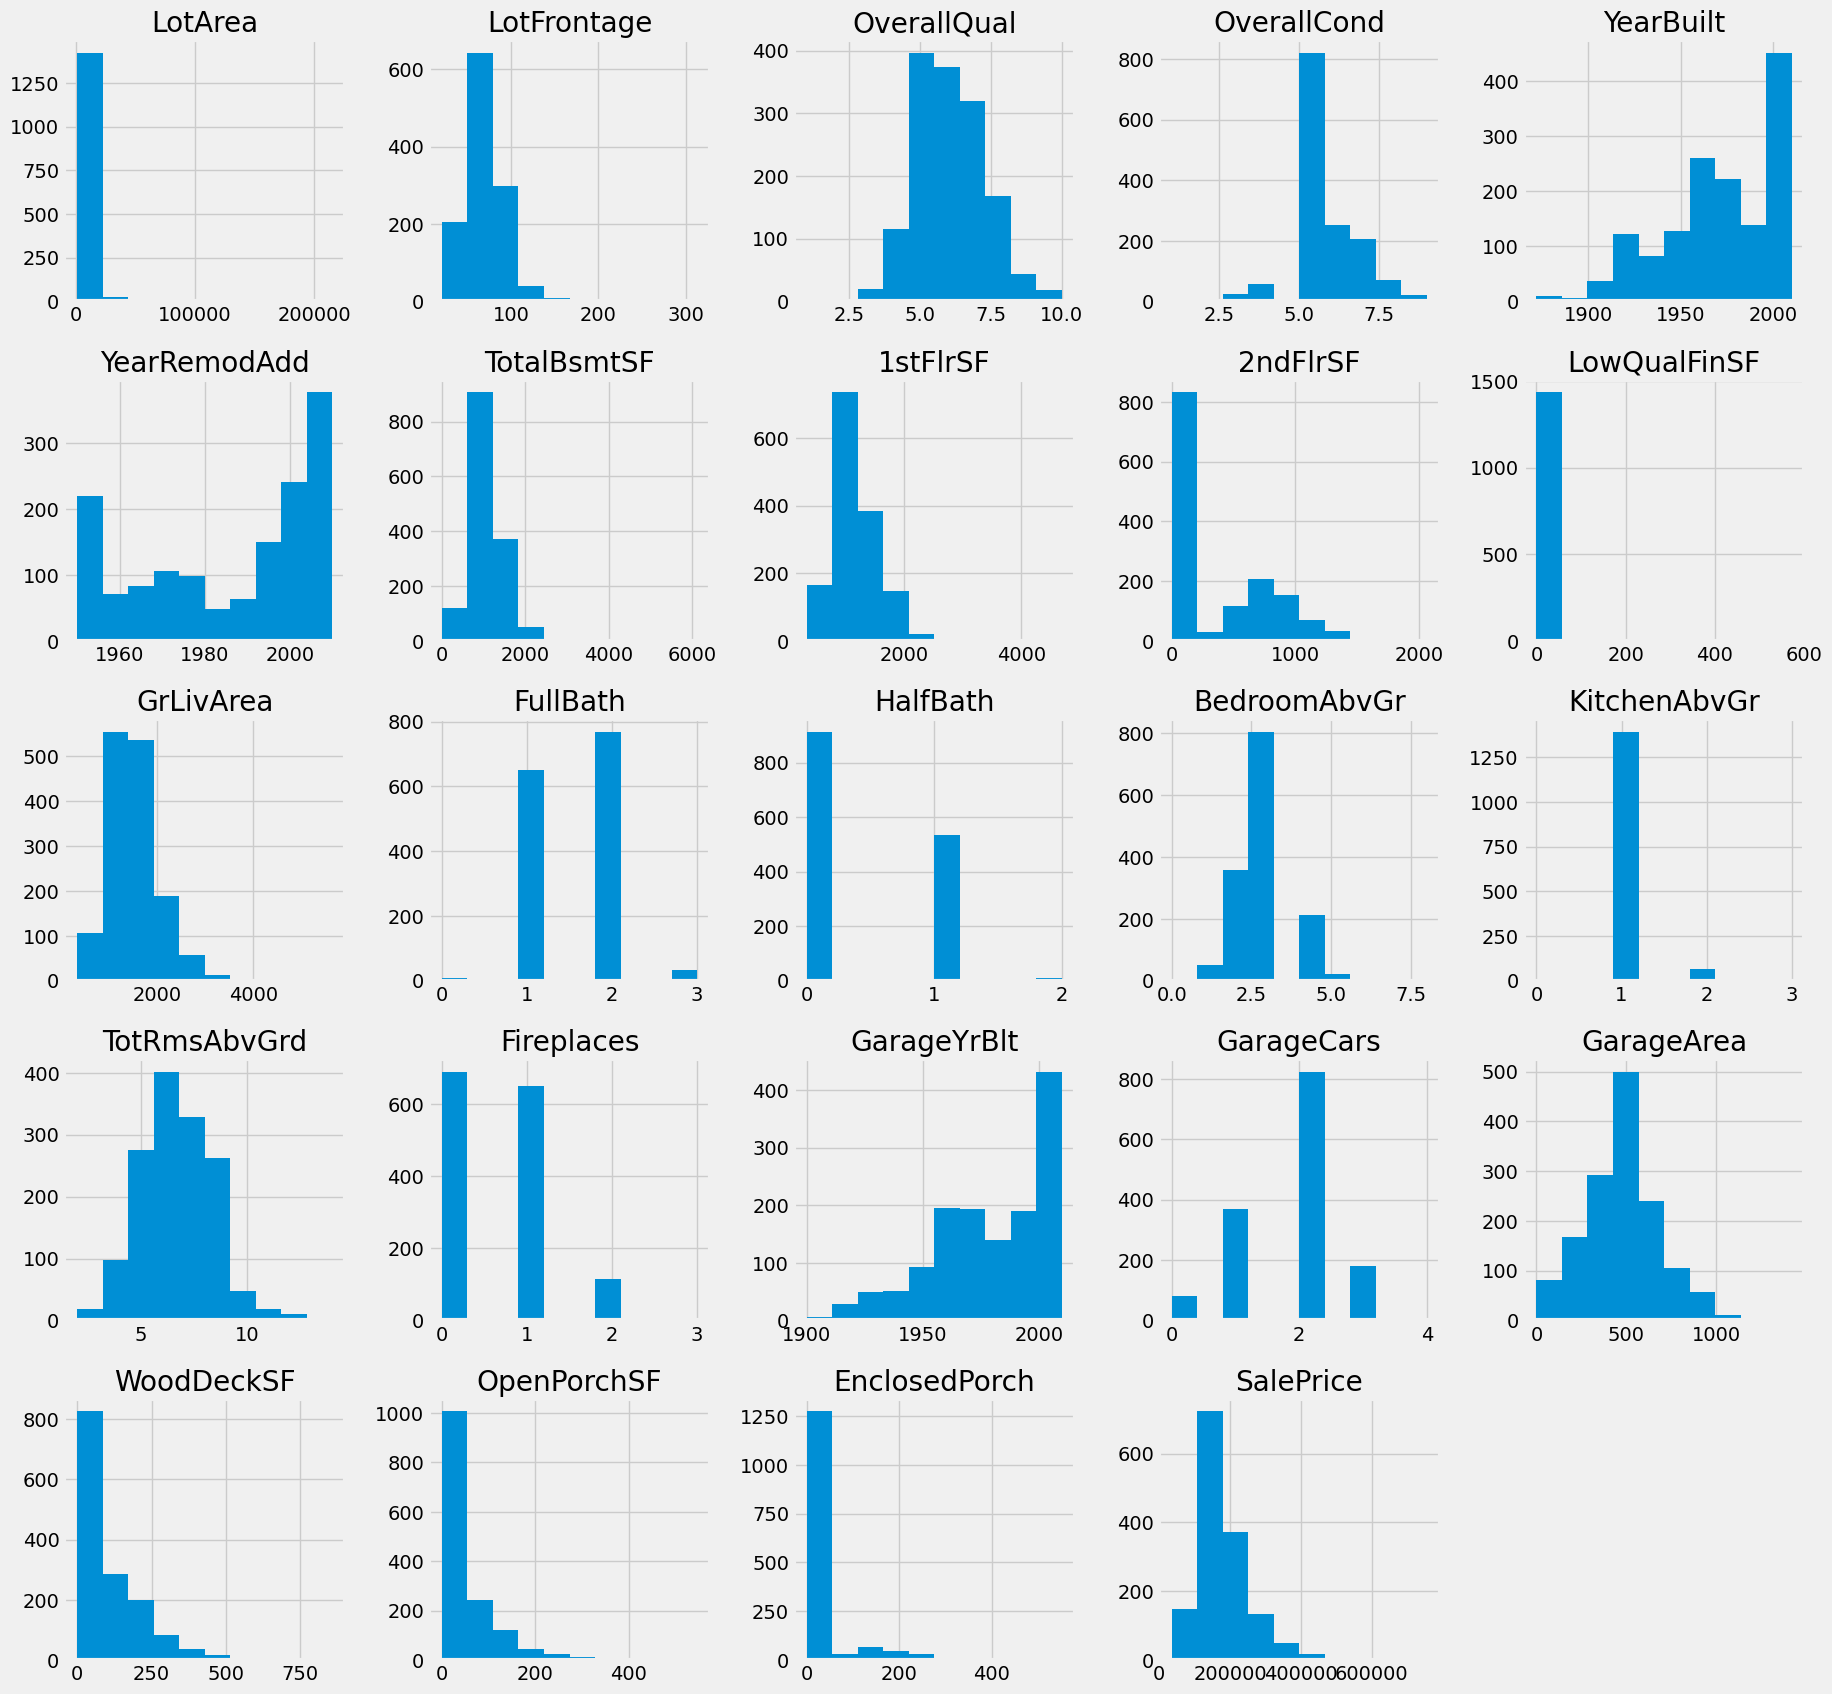

In [12]:
houses.hist(figsize=(20,20));

Now, let's make it interactive with **Plotly**!

# The Plotly Library
---

Plotly is a widely used, user-friendly library for building interactive charts and graphs, and even dashboards. Some benefits of Plotly include:

- Its documentation is easy to use, with plenty of examples
- Visualizations can easily be exported as HTML files
- Building dashboards is straightforward
- The syntax is simple and intuitive

Our first port of call when exploring a new library is its documentation: https://plotly.com/python/

We can see that many different kinds of visualizations are available. Take some time to explore the documentation, noticing the code examples.


Now that we know a bit about Plotly and what kinds of visualizations are appropriate in different situations, we can start building charts!

First, we need to install the Plotly library — it’s one of the few that doesn’t come pre-installed with Anaconda.

If you’re on a Mac, hit command+space and search for the ‘Terminal’. Open it, and type
conda install plotly followed by ‘Enter’.

If you’re on a Windows machine, launch an Anaconda Terminal window via the Anaconda launch screen. Type conda install plotly followed by ‘Enter’.


Let’s explore! We start by importing the plotly library.



In [13]:
# !pip install plotly

In [14]:
import plotly.express as px

ModuleNotFoundError: No module named 'plotly'

The documentation for building histograms with Plotly is here: https://plotly.com/python/histograms/

The documentation gives a demo example of how to build a histogram. You can try running it below. The example uses a built-in Plotly dataset which describes how much restaurant workers are tipped.

Try hovering over the histogram. What appears next to your cursor?

Try the Zoom and Pan functions in the top right hand toolbar.

In [ ]:
df = px.data.tips()
fig = px.histogram(df, x="total_bill")
fig.show()

Now let's introduce some extra parameters to change the appearance and formatting of our histogram.

In [ ]:
fig = px.histogram(df, x="total_bill",
                   title='Histogram of bills',
                   opacity=0.8,
                   color_discrete_sequence=['red'] # color of histogram bars
                   )
fig.show()

Now, can you use this same syntax as above to make a Plotly histogram showing the spread of garage areas?

* Make the bars green, with an opacity of 0.3
* Add the title 'Spread of Garage Areas'


In [ ]:
fig = px.histogram(houses, x="GarageArea",
                  title='Spread of garage areas',
                   opacity=0.5,
                   color_discrete_sequence=['green'])
fig.show()

## <font color='green'> Exercise: Bar charts
---
    
Like histograms, bar charts show the spread of values in a single variable- but they're used for **categorical** or **discrete** variables instead of continuous ones.

For this exercise, you'll need to use a different part of the histogram documentation: https://plotly.com/python/histograms/
    
Make bar charts to show the spread of each of these variables, adjusting the number of bins and the x-axis range to make them as readable as possible:
* Neighborhood
* HouseStyle
    
Add appropriate titles to each chart.
    

In [ ]:
fig = px.histogram(houses, x="Neighborhood",
                  title='Most houses are in North Ames',
                   opacity=0.5,
                   color_discrete_sequence=['green'])
fig.show()

In [ ]:
fig = px.histogram(houses, x="HouseStyle",
                  title='Most properties are single storey',
                   opacity=0.5,
                   color_discrete_sequence=['red'])
fig.show()

<a id="scatter-plots"></a>

# Scatter plots
---
    
Scatterplots show the relationship between pairs of variables.

Often when we're exploring a large data set, we'll want to answer questions like:
- What's the best subset of features to use in my model?
- Which of my features have the strongest relationship with my dependent variable?
- Which features have no correlation with my dependent variable so I can ditch them?
- What kind of relationship exists between a pair of variables? Is it linear, or something else?

Scatterplots can help us answer these questions. We'll typically be interested in:

- Features that are strongly correlated with our dependent variable. If we see evidence of this in a scatterplot and it passes a sense check, this could mean that feature will be a good predictor of our target.
- Features that aren't correlated with our dependent variable. This could mean we can remove this feature from our model.
- Features that are strongly correlated with other features. This is called collinearity and is something we generally want to avoid.


Let's do this using the credit dataset, to show the relationship between income and loan amount.


In [ ]:
houses.plot(kind='scatter',x='YearBuilt',y='SalePrice',xlim=(1850,2020))

What does this scatter plot tell us? 
* It looks like there's a positive correlation between the year a house was built, and its sale price, with newer houses selling for more.

We can change the transparency of the dots to 0.3 using the `alpha` parameter.

In [ ]:
houses.plot(kind='scatter',x='YearBuilt',y='SalePrice',xlim=(1850,2020),alpha=0.3)

## <font color='green'> Exercise: Scatterplots
---
Make scatter plots to answer the following questions.

* Is there a relationship between a lot area and the final sale price? 

* Is there a relationship between the number of rooms (above ground) a property has and its sale price?

You might need to use the following options to format your scatter plots:
* `xlim` and `ylim` to set the axis limits
* `alpha` to set the transparency of the points


In [ ]:
houses.plot(kind='scatter',x='LotArea',y='SalePrice',xlim=(0,40000),alpha=0.3)

In [ ]:
houses.plot(kind='scatter',x='TotRmsAbvGrd',y='SalePrice',xlim=(0,15),alpha=0.3)

Now let's make it interactive! We can start by building an interactive version of a scatter plot, showing year built vs sale price.

In [ ]:
fig = px.scatter(houses, x="YearBuilt", y="SalePrice")
fig.show()

Can you change the value that appears when we hover over each point, so the hover value is the 'Neighbourhood' instead? Use the Plotly scatter plot documentation: https://plotly.com/python/line-and-scatter/

In [ ]:
fig = px.scatter(houses, x="YearBuilt", y="SalePrice",hover_data=['Neighborhood','LotArea'])
fig.show()

How about colouring each point by its house style?

In [ ]:
fig = px.scatter(houses, x="YearBuilt", y="SalePrice",hover_data=['Neighborhood'],color='HouseStyle')
fig.show()

Now, make a plot showing LotArea vs Sale Price.

* Colour the plots by Neighbourhood
* Change the opacity of the points to 0.5
* Add a suitable title

In [ ]:
fig = px.scatter(houses, x="OverallQual", 
                 y="SalePrice",
                 hover_data=['Neighborhood','HouseStyle'],
                 color='Neighborhood',
                title='Quality Score is Correlated with Sale Price')
fig.show()

<a id="pair-plots"></a>

# Pair plots
---
    
Often when we're exploring a large dataset, we'll want to answer questions like:
* What's the best subset of features to use in my model?
* Which of my features have the strongest relationship with my dependent variable?
* Which features have no correlation with my dependent variable so I can ditch them?
* What kind of relationship exists between a pair of variables? Is it linear, or something else?

Pair plots are a quick way of seeing the relationships between all the variables in our dataset in one go, and saves the hassle of having to generate lots of scatter plots one by one. Looking at a pair plot can immediately show us where the strongest relationships are in our data set.
    
**Note:** If your data set is large, these can take quite a while to generate while Python renders the graphics!


In [ ]:
import seaborn as sns

sns.pairplot(houses,vars=['LotArea','Fireplaces','GarageCars','GarageArea','YearBuilt','TotRmsAbvGrd','OverallQual','OverallCond',
                         'SalePrice'])

The matrix is symmetric, so the leading diagonal shows histograms instead of scatterplots (because there’s no value in showing a scatterplot of Sale Price versus Sale Price, for example).

The bottom row shows **Sale Price** on the y-axis, and all the other variables along the x-axis. We can visually inspect this row to see:

- Where the strongest correlations are, or in other words which independent variables look like the best predictors of Sale Price.
- Whether these correlations pass a common sense or reality check.



## <font color='green'> Exercise: Style sheets
---

We've learned to make different kinds of charts, but the design and formatting isn't very exciting so far.

Matplotlib allows very detailed customisation of charts, using 'stylesheets' that set the formatting of everything from fonts used in axis labels, to colours, to grid lines.

Take a look at the stylesheets that come pre-built into Matplotlib here: https://matplotlib.org/3.1.1/gallery/style_sheets/style_sheets_reference.html

Practise using the command `plt.style.use('style sheet name here')` to set a style sheet, and then reproduce some of the visualisations above to check how their appearance changes. 

Note: It's also possible to build your own style sheet- organisations will often do this to make sure their charts are all produced in 'house style'

In [ ]:
print(plt.style.available)

In [ ]:
plt.style.use('grayscale')

In [ ]:
houses.plot(kind='scatter',x='LotArea',y='SalePrice',xlim=(0,40000),alpha=0.3);

<a id="correlation-matrix"></a>

# Correlation matrix
---    
Correlation (or the correlation coefficient) tells us whether there’s an association between two variables. It can only take values from -1 to 1. 

A strongly positive correlation between two variables X and Y means:
* When X is high, Y is high 
* When X is low, Y is low 

A strongly negative correlation between two variables X and Y means:
* When X is high, Y is low 
* When X is low, Y is high 

A correlation close to zero between two variables X and Y means there’s no association between them, and both variables are just doing their own thing. 

A correlation matrix shows the correlation coefficient between every pair of variables in a dataset.


In [ ]:
houses.corr(numeric_only=True)

We can convert this into a heatmap using the Seaborn heatmap function.

In [ ]:
sns.heatmap(houses.corr(numeric_only=True));

## <font color='green'> Exercise: Correlation matrix
---

Can you use the `imshow` function from Plotly to create an interactive correlation plot?

Hint: the documentation is here https://plotly.com/python/heatmaps/

In [ ]:
fig = px.imshow(houses.corr(numeric_only=True))
fig.show()

## Interpreting visualizations
---

Using a combination of the bar, scatter, and correlation plots we’ve made, it’s time to draw some conclusions.

- What are the strongest predictors of sale price?
- What shape is the relationship between these predictors and sale price? 
Is it linear or something else?
- Do the relationships pass a sense check? Is there a plausible causal relationship between them?


# <font color='blue'> Visualizing "the value of X-Men" data </font>

Now, let's use our skills to visualize the value of characters in the X-Men franchise. Using a combination of bar, scatter and line plots, let's visualize aspects of the data.

To do this, we'll be obtaining our data from a project called Mutant Moneyball. The landing page for the dataset is here: https://github.com/EliCash82/mutantmoneyball
    
The documentation on that page also contains the data dictionary.
    
Let's begin by obtaining the data.

# <font color='red'> Exercise: X-Men visualization

The dataset can be found here: https://raw.githubusercontent.com/EliCash82/mutantmoneyball/main/MutantMoneyballOpenData.csv

Try viewing the url in your browser. Can you read this data directly into a pandas DataFrame?

In [ ]:
# data taken from "https://raw.githubusercontent.com/EliCash82/mutantmoneyball/main/MutantMoneyballOpenData.csv"

import pandas as pd

xmen = pd.read_csv('../data/MutantMoneyballOpenData.csv')
xmen.head()

Now, make a Plotly bar chart showing the top 10 X-Men characters with the highest **total** value for issues they appeared in, as sold on ebay.

You'll need to manipulate the data in pandas first.

In [ ]:
import plotly.express as px

top_ten_xmen = xmen.sort_values(by='TotalValue_ebay',ascending=False).head(10)

fig = px.bar(top_ten_xmen, x='Member', y='TotalValue_ebay')
fig.show()

If we assume the value of certain characters is constant over time, we would find a relationship between their value in magazine issues from each decade (i.e. if a character is "valuable" in the 60s, they'll be valuable in the 90s).

Can you test this assumption by producing a Plotly scatter plot showing **the total value of the members' 1960s issue magazines as sold on Heritage** on the x axis, and **the total value of the members' 1990s issue magazines as sold on Heritage** on the y axis? Hovering over each point should show the X-Men member's name.

*NB: Heritage is a comic book auction site, effectively an ebay for comics*

In [ ]:
fig = px.scatter(xmen, x="TotalValue60s_heritage",
                 y="TotalValue90s_heritage",
                 hover_name="Member")

fig.show()

Next, let's try and visualize the data using a bubble chart. The documentation for this is here: https://plotly.com/python/bubble-charts/

Can you make a bubble chart with the same x and y axes as above, but with bubble size corresponding to the **total number of issues the X-Men character appeared in**?

Hovering over each bubble should show the X-Men member's name.

In [ ]:
fig = px.scatter(xmen, x="TotalValue60s_heritage",
                 y="TotalValue90s_heritage",
                 size="TotalIssues",
                 hover_name="Member",
                 size_max=60)

fig.show()